# S0235b: a simple receiver-function workflow
Compare **deglitched** and **Dahmen denoised** data using three methods:
1. Bayesian Gaussian-pulse deconvolution (standard, non-overlapping mode).
2. Water-level deconvolution.
3. Full-window multitaper deconvolution.

We load physical ZNE waveforms, put both products in velocity units, reference an **absolute catalog P pick**, rotate to RTZ, bandpass at **2-8 s**, and calculate radial P-to-S RFs over **0-20 s**. The source is the **whole Z analysis window**, not an isolated first P pulse. There is no free-surface transform, polarity flip, conversion-peak alignment, or parameter tuning to match a paper.

**Important:** the package's legacy Bayesian sampler has known prior/proposal inconsistencies. Its retained mean and best-likelihood RF are exploratory, not calibrated posterior estimates. The API calls the latter `map_receiver_function`; it is not a certified MAP. A longer chain cannot by itself fix these issues. See [limitations](../docs/limitations.md).

Run the cells in order. Saved figures let you inspect the demonstration without rerunning the sampler. This is a processing example, **not a convergence or structural-inversion study**.

## 1. Setup
From the repository root, install the notebook dependencies into your chosen environment:
```bash
python -m pip install -e '.[notebook]'
python -m jupyter lab examples/S0235b_RF_demo.ipynb
```
Use that environment's Python kernel. The local `insight_data` files must already be imported; no downloads or CPS compilation are needed. Both datasets are processing versions of the **same earthquake**, not independent observations.

In [1]:
from dataclasses import asdict, replace
from pathlib import Path
from time import perf_counter
import json
import os

# Keep notebook imports usable on machines with a read-only home cache.
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ.get("TMPDIR", "/tmp")) / "rfpy-matplotlib"))
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import numpy as np
import matplotlib.pyplot as plt
from obspy import UTCDateTime
from scipy.signal import fftconvolve
from IPython import get_ipython

from bayesian_rf import BayesianRFConfig, preprocess_zne_ps_data
from bayesian_rf.data import load_insight_waveforms
from bayesian_rf.deconvolution import (
    ClassicalRF, from_bayesian_samples,
    run_bayesian_deconvolution, waterlevel_rf, multitaper_rf,
)

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Works from the checkout root or examples/. Override only if opened elsewhere.
start = Path(os.environ.get("RFPY_PROJECT_ROOT", Path.cwd())).expanduser().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "insight_data/manifest.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open from this checkout, or set RFPY_PROJECT_ROOT to its root.")
DATA = ROOT / "insight_data"
OUTPUT = Path(os.environ.get("RFPY_DEMO_OUTPUT", ROOT / "results/s0235b_notebook"))
print("Package checkout:", ROOT.name)

Package checkout: bayesian_rfpy


In [2]:
EVENT = "S0235b"
DATASETS = ("deglitched", "denoised")

# A single demonstration chain per product, not a production posterior.
N_ITERATIONS = int(os.environ.get("RFPY_DEMO_ITERATIONS", "100000"))
if N_ITERATIONS < 20:
    raise ValueError("Use at least 20 iterations, even for a smoke test.")
BURNIN = N_ITERATIONS // 2
SAVE_EVERY = max(1, (N_ITERATIONS - BURNIN) // 500)
SEED = 42

CONFIG = BayesianRFConfig(
    min_lag=0.0, max_lag=20.0,
    min_period=2.0, max_period=8.0,
    freqmin=1/8, freqmax=1/2,
    pre_arrival=20.0, post_arrival=55.0,
    target_sampling_rate=4.0, rf_output_sampling_rate=10.0,
    iterations=N_ITERATIONS, burnin=BURNIN, save_every=SAVE_EVERY,
    component_separation_factor=1.0, random_seed=SEED,
)
WATER_LEVEL = 0.01             # Fraction of maximum source spectral power.
GAUSSIAN_SIGMA_S = 0.25         # Additional display smoothing, not the Bayesian width prior.
TIME_BANDWIDTH, N_TAPERS = 2.5, 3
COLORS = {"Bayesian mean": "#b34f32", "Water level": "#187b75", "Multitaper": "#315da8"}
print(f"Bayesian run: {N_ITERATIONS:,} iterations/product; {BURNIN:,} burn-in.")
print("Sampled Gaussian-width bounds (s):", CONFIG.width_bounds())

Bayesian run: 100,000 iterations/product; 50,000 burn-in.
Sampled Gaussian-width bounds (s): (0.2, 0.8)


## 2. Load data and check times/units
The deglitched file contains **displacement (m)**; the denoised archive contains **velocity (m/s)**. We first load native data, then differentiate the displacement **once**. Neither product needs another instrument-response removal.

The two records start at different UTC times. We never reuse a relative arrival offset between them. File checksums are verified by the loader.

In [3]:
native, velocity, metadata = {}, {}, {}
for name in DATASETS:
    native[name], metadata[name] = load_insight_waveforms(DATA, EVENT, name, velocity=False)
    record = metadata[name]
    assert record["parent_phase"] == "P"
    stream = native[name].copy()
    units = record["products"][name]["units"]
    if units == "m":
        stream.detrend("linear").differentiate(method="gradient")
    elif units != "m/s":
        raise ValueError(f"Unexpected physical units: {units}")
    velocity[name] = stream

P_TIME = UTCDateTime(metadata["denoised"]["parent_arrival_utc"])
BACK_AZIMUTH = metadata["denoised"]["back_azimuth_deg"]
assert BACK_AZIMUTH is not None
print(f"Absolute P pick: {P_TIME}; back azimuth: {BACK_AZIMUTH:.3f} degrees")
for name in DATASETS:
    stream = native[name]
    assert UTCDateTime(metadata[name]["parent_arrival_utc"]) == P_TIME
    assert not stream.get_gaps(), "Resolve gaps/overlaps before rotation."
    for component in "ZNE":
        assert len(stream.select(component=component)) == 1
    print(f"{name:10s}  {stream[0].stats.starttime}  "
          f"P offset = {float(P_TIME - stream[0].stats.starttime):.6f} s  "
          f"native units = {metadata[name]['products'][name]['units']}")

Absolute P pick: 2019-07-26T12:19:18.032523Z; back azimuth: 77.073 degrees
deglitched  2019-07-26T12:15:38.758000Z  P offset = 219.274523 s  native units = m
denoised    2019-07-26T12:16:16.977000Z  P offset = 181.055523 s  native units = m/s


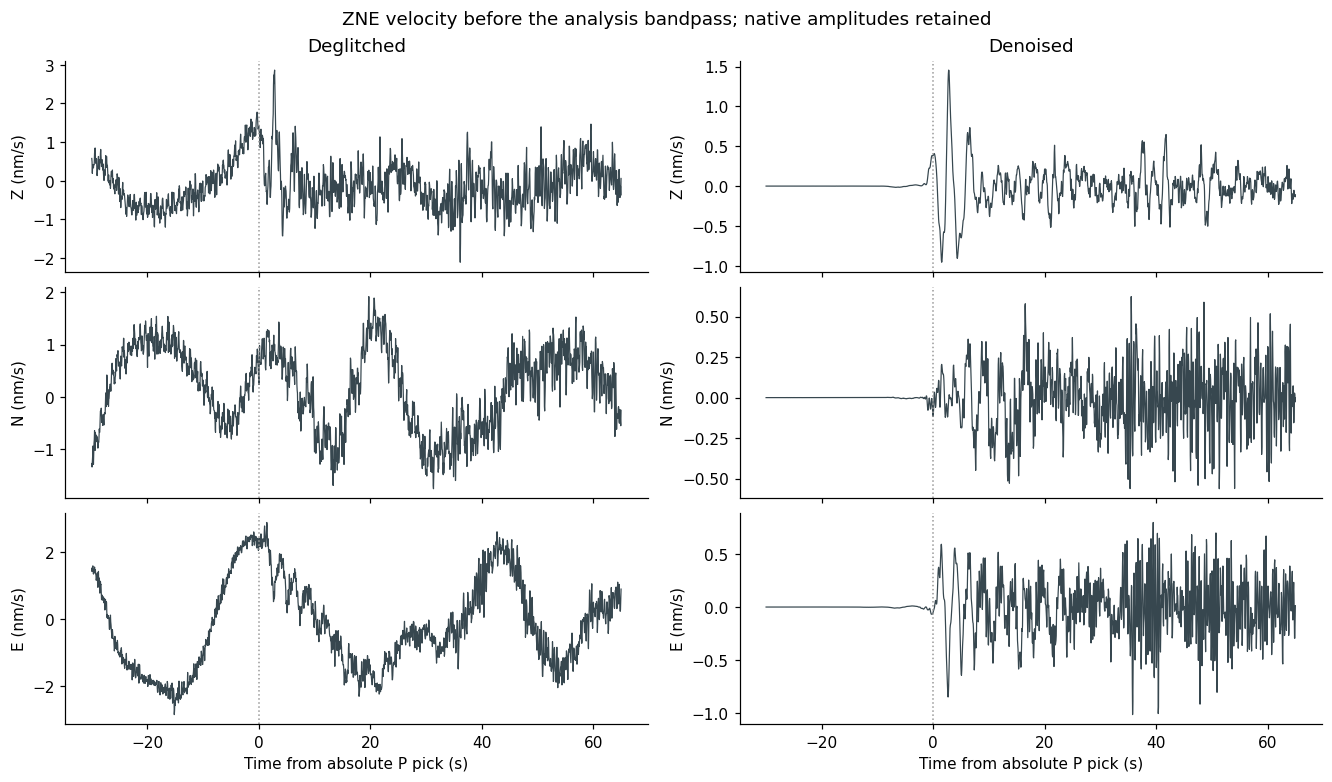

In [4]:
fig_raw, axes = plt.subplots(3, 2, figsize=(12, 7), sharex=True, constrained_layout=True)
for col, name in enumerate(DATASETS):
    for row, component in enumerate("ZNE"):
        tr = velocity[name].select(component=component)[0]
        time = tr.times(reftime=P_TIME)
        keep = (time >= -30) & (time <= 65)
        axes[row, col].plot(time[keep], tr.data[keep] * 1e9, lw=0.8, color="#37474f")
        axes[row, col].axvline(0, color="0.6", ls=":", lw=1)
        axes[row, col].set_ylabel(f"{component} (nm/s)")
    axes[0, col].set_title(name.capitalize())
    axes[-1, col].set_xlabel("Time from absolute P pick (s)")
fig_raw.suptitle("ZNE velocity before the analysis bandpass; native amplitudes retained")
plt.show()

## 3. Filter, rotate, and select the P window
`preprocess_zne_ps_data` makes a copy, aligns component sample grids, removes the mean, applies a 2% edge taper and a **two-corner zero-phase 0.125-0.5 Hz bandpass**, resamples to 4 Hz, and rotates N/E to R/T using the catalog back azimuth. Internally, this uses ObsPy's `rotate_ne_rt` convention.

It then extracts approximately **P-20 to P+55 s** and subtracts each component's pre-P mean. Z is the source; R is the response; T is displayed as a quality-control component. The window is snapped to the analysis sample grid (at most half a 0.25-s sample from the requested boundary).

We retain **the whole 75-s Z window**, including its coda. This assumption affects RFs and can be investigated separately. Zero-phase filtering here is for RF processing, not first-motion polarity picking.

In [5]:
processed, waveform_time, noise_mask = {}, {}, {}
for name, stream in velocity.items():
    offset = float(P_TIME - stream[0].stats.starttime)
    if any(tr.stats.starttime > P_TIME - CONFIG.pre_arrival or
           tr.stats.endtime < P_TIME + CONFIG.post_arrival for tr in stream):
        raise ValueError(f"{name} does not cover the full requested window.")
    processed[name] = preprocess_zne_ps_data(
        stream, p_arrival_offset_s=offset,
        back_azimuth=BACK_AZIMUTH, config=CONFIG,
    )
    data = processed[name]
    # Recover the nearest-sample window origin for this particular input grid.
    start = max(tr.stats.starttime for tr in stream)
    requested_sample = float(P_TIME - start - CONFIG.pre_arrival) / data.dt
    actual_start = start + round(requested_sample) * data.dt
    waveform_time[name] = np.arange(data.parent.size) * data.dt + float(actual_start - P_TIME)
    noise_mask[name] = (waveform_time[name] >= -20) & (waveform_time[name] < -5)
    assert noise_mask[name].sum() >= 8
    assert data.parent.shape == data.daughter.shape == data.transverse.shape
    assert np.isfinite([data.parent, data.daughter, data.transverse]).all()
    print(f"{name:10s}: {data.parent.size} samples, dt={data.dt:g} s; "
          f"{noise_mask[name].sum()} noise samples in [-20, -5) s")

deglitched: 301 samples, dt=0.25 s; 60 noise samples in [-20, -5) s
denoised  : 301 samples, dt=0.25 s; 60 noise samples in [-20, -5) s


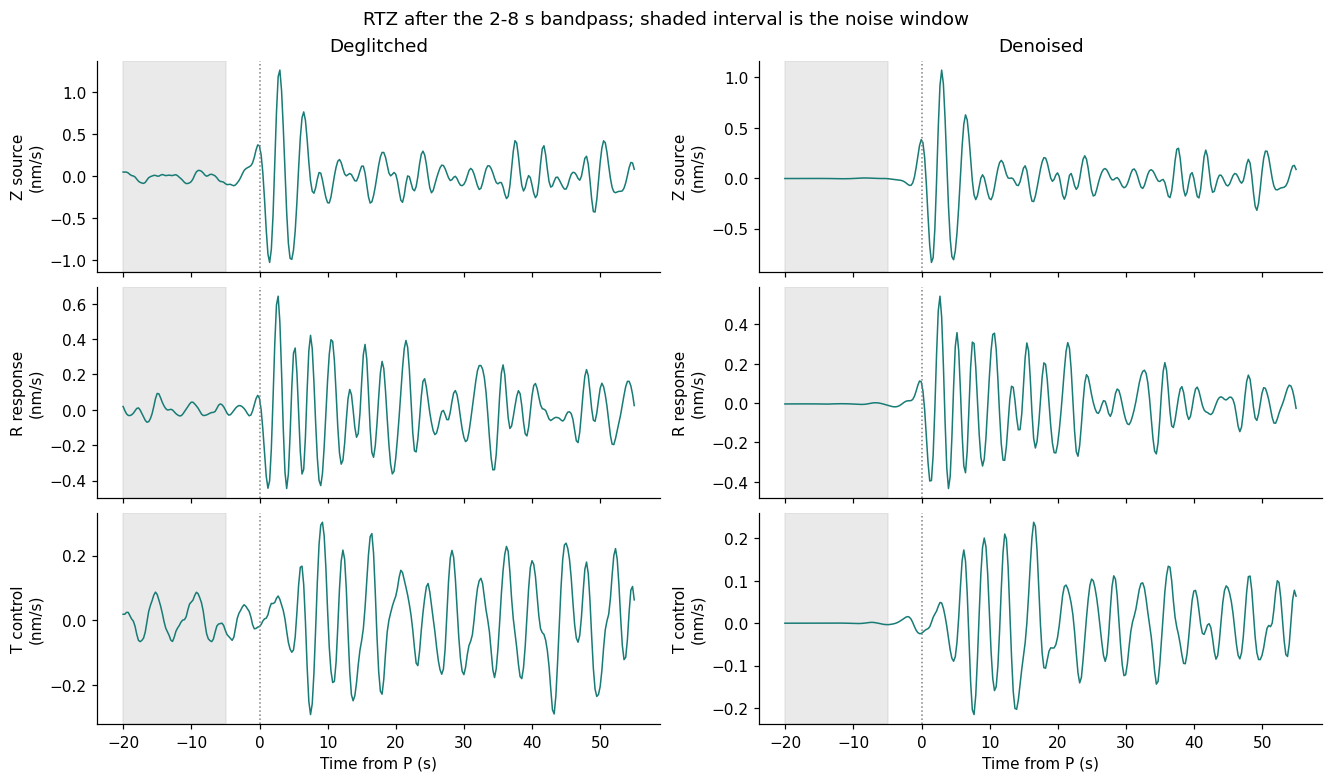

In [6]:
fig_rtz, axes = plt.subplots(3, 2, figsize=(12, 7), sharex=True, constrained_layout=True)
for col, name in enumerate(DATASETS):
    data = processed[name]
    for row, (label, values) in enumerate(zip(
        ("Z source", "R response", "T control"),
        (data.parent, data.daughter, data.transverse),
    )):
        ax = axes[row, col]
        ax.plot(waveform_time[name], values * 1e9, color="#187b75", lw=1)
        ax.axvline(0, color="0.5", ls=":", lw=1)
        ax.axvspan(-20, -5, color="0.8", alpha=0.4)
        ax.set_ylabel(f"{label}\n(nm/s)")
    axes[0, col].set_title(name.capitalize())
    axes[-1, col].set_xlabel("Time from P (s)")
fig_rtz.suptitle("RTZ after the 2-8 s bandpass; shaded interval is the noise window")
plt.show()

## 4. Calculate all three RF estimates
Each method receives the same processed Z and R arrays for a given product.

- **Water level:** 0.01 of peak Z spectral power.
- **Multitaper:** full-window DPSS, time-bandwidth 2.5 and three tapers. Stabilization uses **Z noise**, not R noise.
- **Bayesian:** standard non-overlapping Gaussian pulses and the existing type-3 correlated-noise model. We supply **R noise** for its residual-noise initialization.

Both noise windows are P-20 to P-5 s, avoiding the immediate P onset. Spectral methods also apply their internal 10% Tukey taper. The Bayesian fit uses the unmodified analysis arrays, so the objectives are not identical. The Bayesian warning is expected. Runtime is printed and depends on the machine; the saved demonstration took about a minute for both chains.

In [7]:
estimates = {}
for name, data in processed.items():
    z, r, dt = data.parent, data.daughter, data.dt
    estimates[name] = {
        "Water level": waterlevel_rf(z, r, dt, waterlevel=WATER_LEVEL),
        "Multitaper": multitaper_rf(
            z, r, dt, source_noise=z[noise_mask[name]],
            time_bandwidth=TIME_BANDWIDTH, tapers=N_TAPERS,
        ),
    }
print("Water-level and multitaper calculations finished for both datasets.")

Water-level and multitaper calculations finished for both datasets.


In [8]:
bayesian, elapsed = {}, {}
for name, data in processed.items():
    print(f"Running Bayesian demonstration: {name}...", flush=True)
    started = perf_counter()
    bayesian[name] = run_bayesian_deconvolution(
        data.parent, data.daughter, data.daughter[noise_mask[name]], data.dt,
        config=replace(CONFIG),
    )
    elapsed[name] = perf_counter() - started
    result = bayesian[name]
    print(f"  {elapsed[name]:.1f} s; {len(result.saved_counts)} retained samples; "
          f"acceptance={result.acceptance_rate:.3f}. Convergence is NOT established.")

Running Bayesian demonstration: deglitched...


/var/folders/dx/6jvq8vs10977x01yfk7dw1vw0000gr/T/ipykernel_16860/1623979529.py:5: RuntimeWarning: Legacy Bayesian deconvolution has unresolved prior/proposal inconsistencies; do not interpret its sample spread as calibrated uncertainty. See docs/limitations.md.
  bayesian[name] = run_bayesian_deconvolution(


  27.2 s; 500 retained samples; acceptance=0.183. Convergence is NOT established.
Running Bayesian demonstration: denoised...


  25.5 s; 500 retained samples; acceptance=0.170. Convergence is NOT established.


## 5. Compare at a common zero-lag resolution
Raw Bayesian output is a **kernel density**, whereas the classical RFs use **impulse masses and a Z-self-RF normalization**. Overlaying those arrays directly would give a misleading amplitude comparison.

For display only, convert Bayesian densities to impulse-mass spectra. Use the pointwise minimum of the water-level and multitaper Z self-transfers from **both products**, then apply the same additional Gaussian (sigma 0.25 s). Normalize everything by that common positive Z self-pulse at zero lag. This smooths; it never sharpens or independently rescales/flips radial peaks.

This makes zero-lag resolution/normalization comparable. It does **not** undo the multitaper estimator's lag-dependent bias, equalize every method's effective resolution, or calibrate Bayesian uncertainty. Negative displayed lags can contain filter ringing even though the Bayesian model is causal.

In [9]:
nfft = estimates["denoised"]["Water level"].nfft
dt = processed["denoised"].dt
assert all(e.nfft == nfft and e.dt == dt for group in estimates.values() for e in group.values())
common_transfer = np.minimum.reduce([
    e.self_transfer for group in estimates.values() for e in group.values()
])
assert np.all(common_transfer >= 0)

curves, self_pulses = {}, {}
for name, result in bayesian.items():
    spectra = from_bayesian_samples(
        np.stack([result.mean_receiver_function, result.map_receiver_function]),
        result.lag_times, dt, nfft,
    )
    estimates[name]["Bayesian mean"] = ClassicalRF(spectra[0], np.ones_like(common_transfer), nfft, dt)
    estimates[name]["Bayesian best fit"] = ClassicalRF(spectra[1], np.ones_like(common_transfer), nfft, dt)
    curves[name] = {}
    for method, estimate in estimates[name].items():
        lag, radial_rf, self_rf = estimate.waveform(
            sigma_s=GAUSSIAN_SIGMA_S, min_lag=-5, max_lag=20,
            common_transfer=common_transfer,
        )
        curves[name][method] = radial_rf
        self_pulses[(name, method)] = self_rf
reference_self = next(iter(self_pulses.values()))
assert all(np.allclose(pulse, reference_self) for pulse in self_pulses.values())
assert np.isclose(reference_self[np.argmin(abs(lag))], 1.0)
print("All methods/products share the same positive unit-height zero-lag self pulse.")

All methods/products share the same positive unit-height zero-lag self pulse.


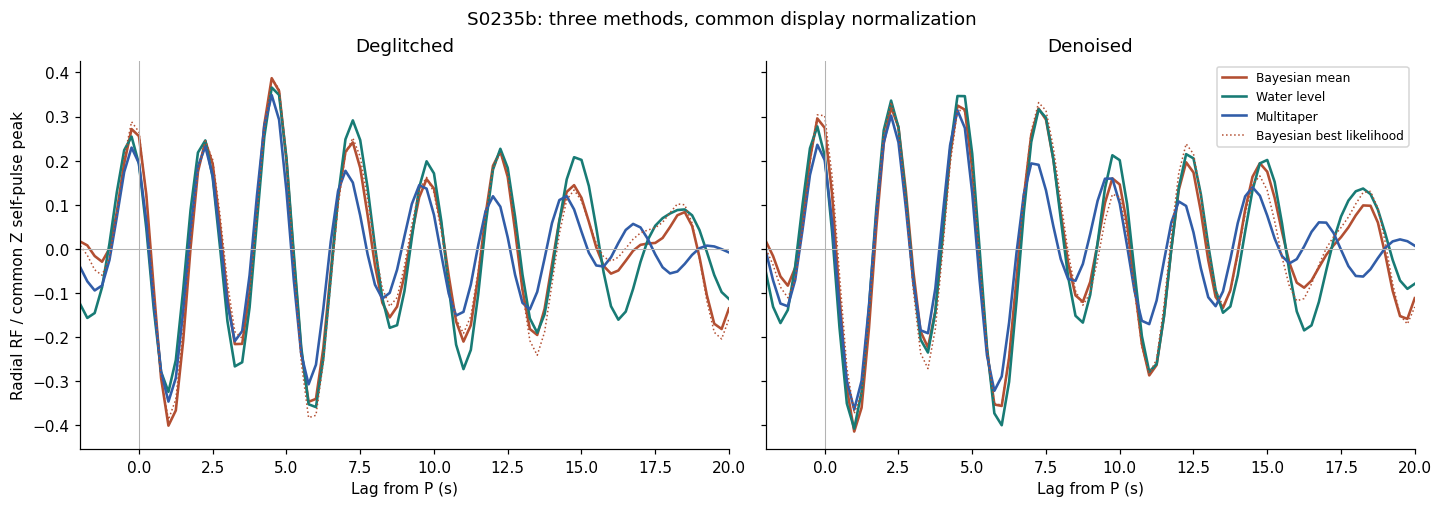

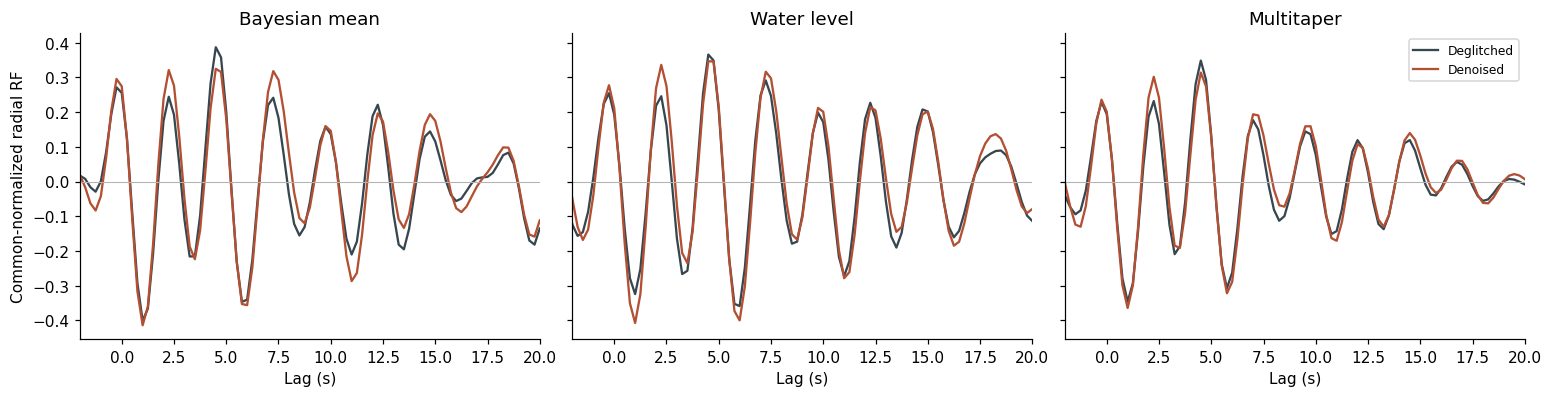

In [10]:
fig_rf, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True, constrained_layout=True)
for ax, name in zip(axes, DATASETS):
    for method, color in COLORS.items():
        ax.plot(lag, curves[name][method], label=method, color=color, lw=1.7)
    ax.plot(lag, curves[name]["Bayesian best fit"], color=COLORS["Bayesian mean"],
            ls=":", lw=1, label="Bayesian best likelihood")
    ax.axhline(0, color="0.7", lw=0.7)
    ax.axvline(0, color="0.7", lw=0.7)
    ax.set(title=name.capitalize(), xlabel="Lag from P (s)", xlim=(-2, 20))
axes[0].set_ylabel("Radial RF / common Z self-pulse peak")
axes[1].legend(fontsize=8)
fig_rf.suptitle("S0235b: three methods, common display normalization")
plt.show()

fig_products, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True, sharey=True, constrained_layout=True)
for ax, method in zip(axes, COLORS):
    ax.plot(lag, curves["deglitched"][method], color="#37474f", label="Deglitched")
    ax.plot(lag, curves["denoised"][method], color="#b34f32", label="Denoised")
    ax.axhline(0, color="0.7", lw=0.7)
    ax.set(title=method, xlabel="Lag (s)", xlim=(-2, 20))
axes[0].set_ylabel("Common-normalized radial RF")
axes[-1].legend(fontsize=8)
plt.show()

## 6. Check the Bayesian waveform reconstruction
Reconstruct R directly as **dt times the linear convolution of Z with the native best-fit Bayesian kernel**. Do not convolve with the peak-normalized/smoothed curves above. The model is evaluated on the fitting grid, not the 10-Hz display grid.

This check uses no fitted amplitude or time shift. The ordinary RMS residual is descriptive: it is not the sampler's correlated-noise likelihood and cannot certify convergence. The spectral estimators' different objectives, tapering and regularization mean that the same residual would not be a fair method ranking.

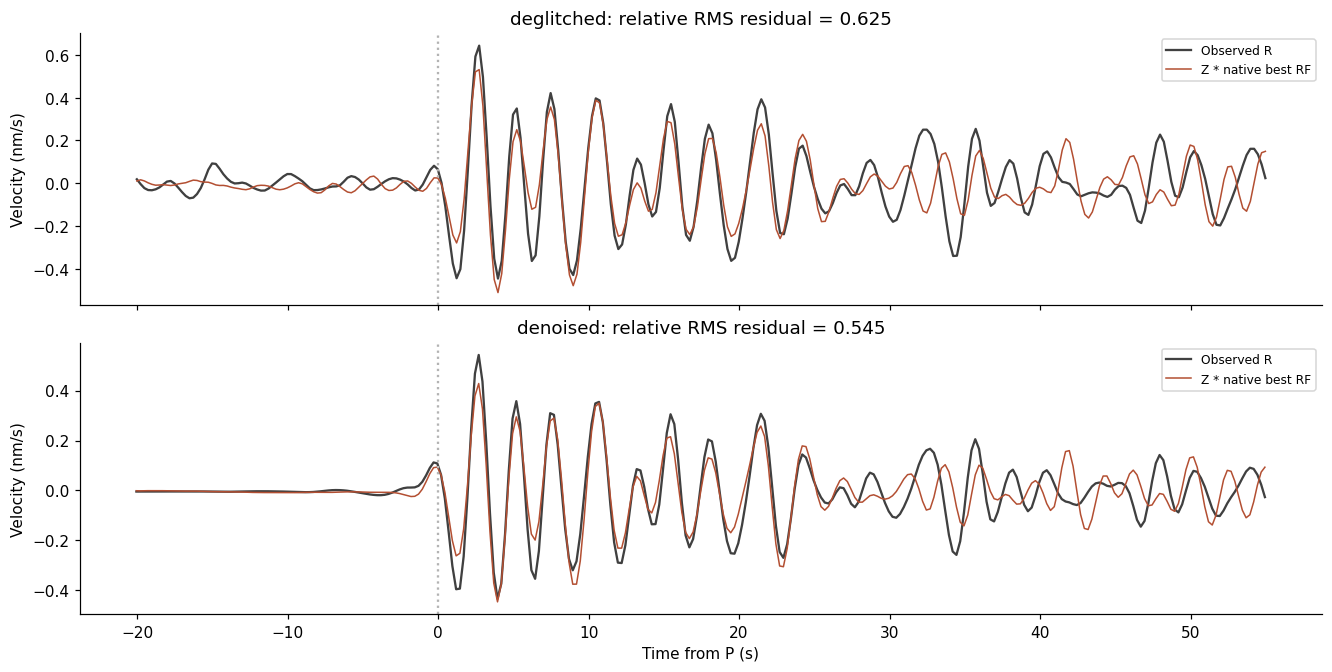

In [11]:
fig_recovery, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
predictions = {}
for ax, name in zip(axes, DATASETS):
    data, result = processed[name], bayesian[name]
    kernel_lag = np.arange(CONFIG.min_lag, CONFIG.max_lag + 0.5 * data.dt, data.dt)
    kernel = np.zeros_like(kernel_lag)
    for pulse in result.map_components:
        kernel += pulse.amplitude * np.exp(-0.5 * ((kernel_lag - pulse.center) / pulse.width)**2)
    predicted = fftconvolve(data.parent, kernel, mode="full")[:len(data.parent)] * data.dt
    predictions[name] = predicted
    relative_rms = np.linalg.norm(predicted - data.daughter) / np.linalg.norm(data.daughter)
    ax.plot(waveform_time[name], data.daughter * 1e9, color="0.25", label="Observed R")
    ax.plot(waveform_time[name], predicted * 1e9, color="#b34f32", lw=1, label="Z * native best RF")
    ax.set(title=f"{name}: relative RMS residual = {relative_rms:.3f}", ylabel="Velocity (nm/s)")
    ax.axvline(0, color="0.7", ls=":")
    ax.legend(fontsize=8)
axes[-1].set_xlabel("Time from P (s)")
plt.show()

## 7. Save the comparison
Outputs go to the ignored `results/s0235b_notebook/` folder, not into the source-data directories. The NPZ files keep the displayed curves **separate** from native Bayesian densities, together with the input arrays and retained samples. These display RFs are not automatically suitable for structural inversion without a matched forward operator.

In [12]:
OUTPUT.mkdir(parents=True, exist_ok=True)
for name, result in bayesian.items():
    np.savez_compressed(
        OUTPUT / f"{EVENT}_{name}.npz",
        comparison_lag_s=lag, comparison_bayesian_mean=curves[name]["Bayesian mean"],
        comparison_bayesian_best=curves[name]["Bayesian best fit"],
        comparison_waterlevel=curves[name]["Water level"],
        comparison_multitaper=curves[name]["Multitaper"], common_self_rf=reference_self,
        native_bayesian_lag_s=result.lag_times,
        native_bayesian_mean=result.mean_receiver_function,
        native_bayesian_best=result.map_receiver_function,
        native_bayesian_samples=result.saved_receiver_functions,
        pulse_counts=result.saved_counts, sigma=result.saved_sigma, noise_lambda=result.saved_lambda,
        waveform_time_s=waveform_time[name], dt=processed[name].dt,
        z=processed[name].parent, r=processed[name].daughter,
        t=processed[name].transverse, bayesian_reconstruction=predictions[name],
    )
for figure, filename in [
    (fig_raw, "01_zne_velocity.png"), (fig_rtz, "02_filtered_rtz.png"),
    (fig_rf, "03_rf_methods.png"), (fig_products, "04_data_products.png"),
    (fig_recovery, "05_bayesian_reconstruction.png"),
]:
    figure.savefig(OUTPUT / filename, dpi=160)
settings = {
    "event": EVENT, "datasets": list(DATASETS), "p_pick_utc": str(P_TIME),
    "back_azimuth_deg": BACK_AZIMUTH, "config": asdict(CONFIG),
    "waterlevel": WATER_LEVEL, "gaussian_sigma_s": GAUSSIAN_SIGMA_S,
    "time_bandwidth": TIME_BANDWIDTH, "tapers": N_TAPERS,
    "noise_window_s": [-20, -5], "elapsed_seconds": elapsed,
    "convergence_verified": False, "bayesian_posterior_validated": False,
    "inputs": metadata["denoised"]["products"],
}
(OUTPUT / "settings.json").write_text(json.dumps(settings, indent=2, allow_nan=False) + "\n")
print(f"Saved {len(list(OUTPUT.glob('*')))} files to {OUTPUT.name}/")
plt.close("all")

Saved 8 files to s0235b_notebook/


## What to look for
- Do the products agree after correcting **units and absolute timing**?
- Are conversion features repeatable across methods, or dominated by zero-lag/filter ringing?
- Does a plausible RF also reconstruct the radial waveform?
- What changes if you vary the source window, water level, taper settings or noise interval?

Do not infer three independent confirmations: methods share inputs and filtering, and denoised/deglitched traces share the same recorded event. Avoid selecting settings solely to force expected peaks.

For routine preprocessing, `bayesian_rf.data.preprocess_insight_event(DATA, EVENT, dataset, CONFIG)` combines the loading, unit conversion, catalog timing and ZNE processing steps used above. For production uncertainty work, first address the legacy sampler limitations and then assess independent chains; this notebook intentionally does neither.